In [ ]:
pip install xgboost

Loaded 11598 apps; kept 11520 unique apps with 139 system-call features
Benign: 1791 | Malicious: 9729  (malware is 84.5% of the data)

>>> A. Main run: random 80/20 split
      TCN (Multi-Branch)   trained in 673.4s
      BiLSTM               trained in 618.1s
      Transformer          trained in 1335.0s

=== A. RANDOM 80/20 TEST SET ===
                    Accuracy  Precision  Recall (malware caught)  Specificity (benign cleared)      F1  ROC-AUC
TCN (Multi-Branch)    0.9453     0.9633                   0.9723                        0.7989  0.9678   0.9554
BiLSTM                0.9080     0.9733                   0.9162                        0.8631  0.9439   0.9523
Transformer           0.9093     0.9796                   0.9116                        0.8966  0.9444   0.9691
XGBoost               0.9731     0.9901                   0.9779                        0.9469  0.9840   0.9915

Top 50 system calls were selected on the training data only. Top 15:
   1. ftruncate64           

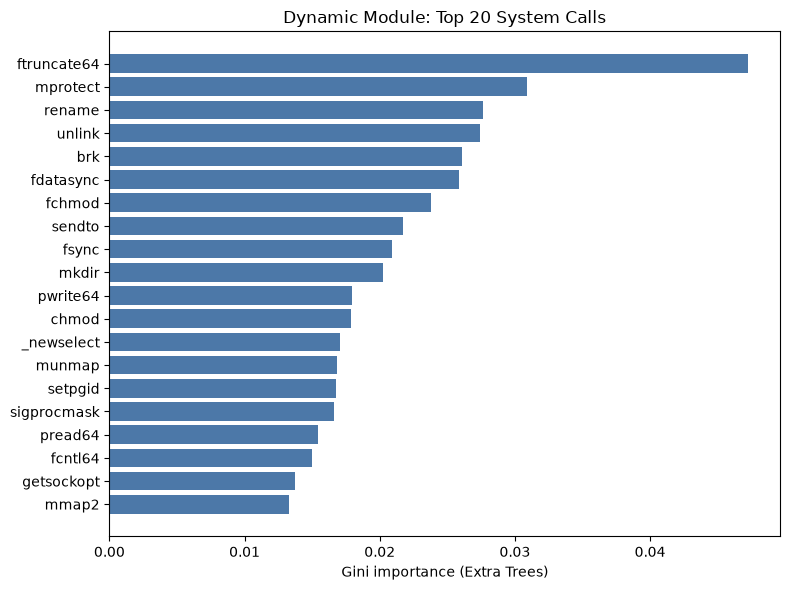

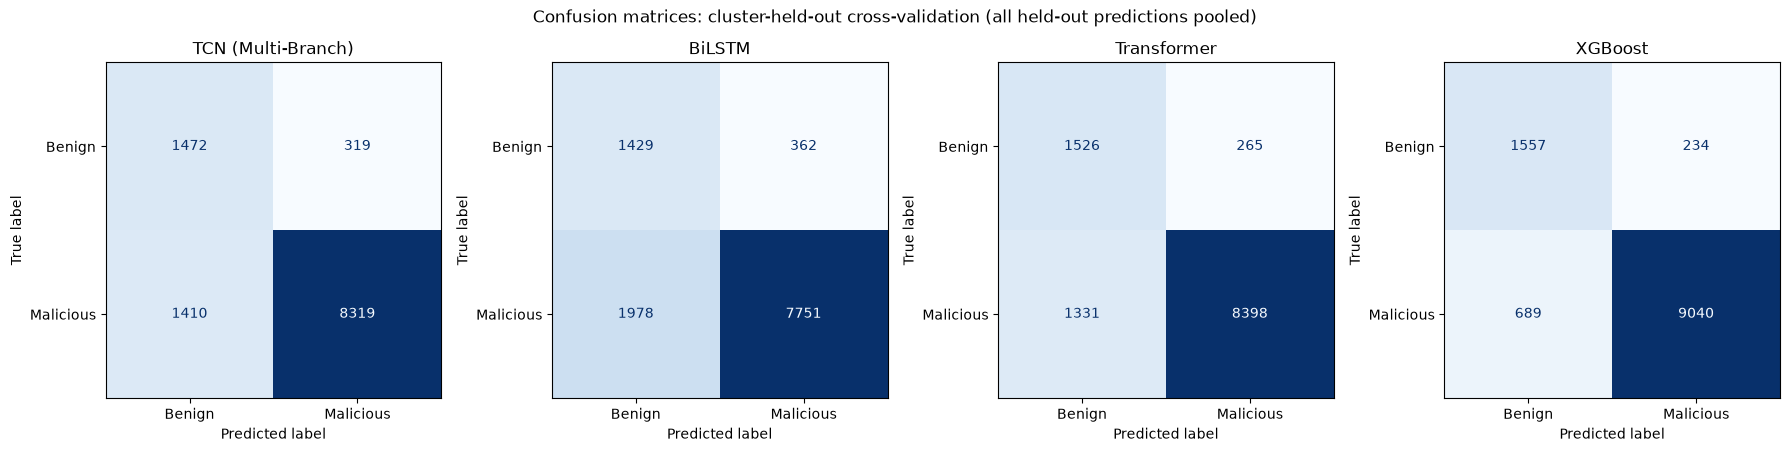

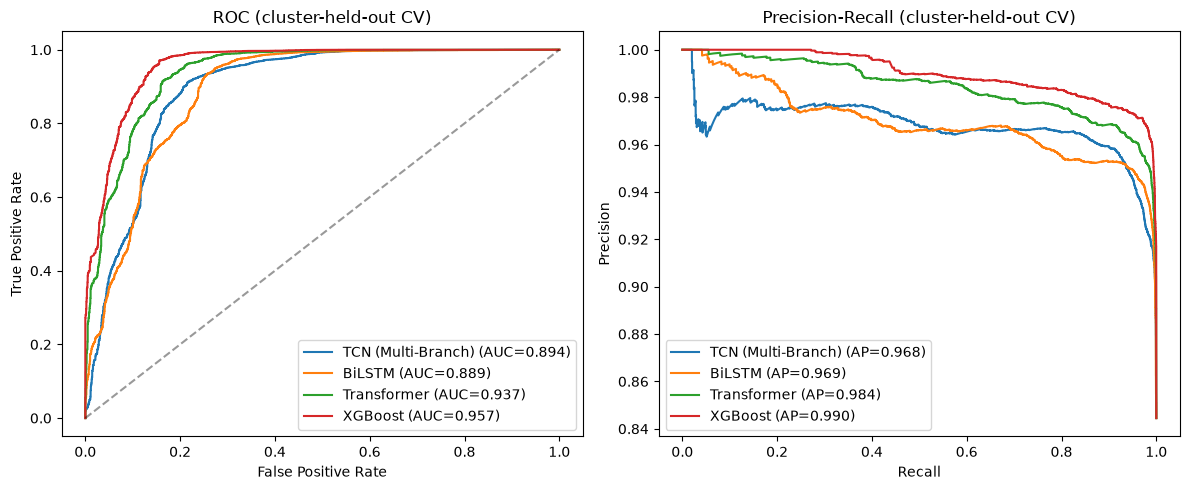

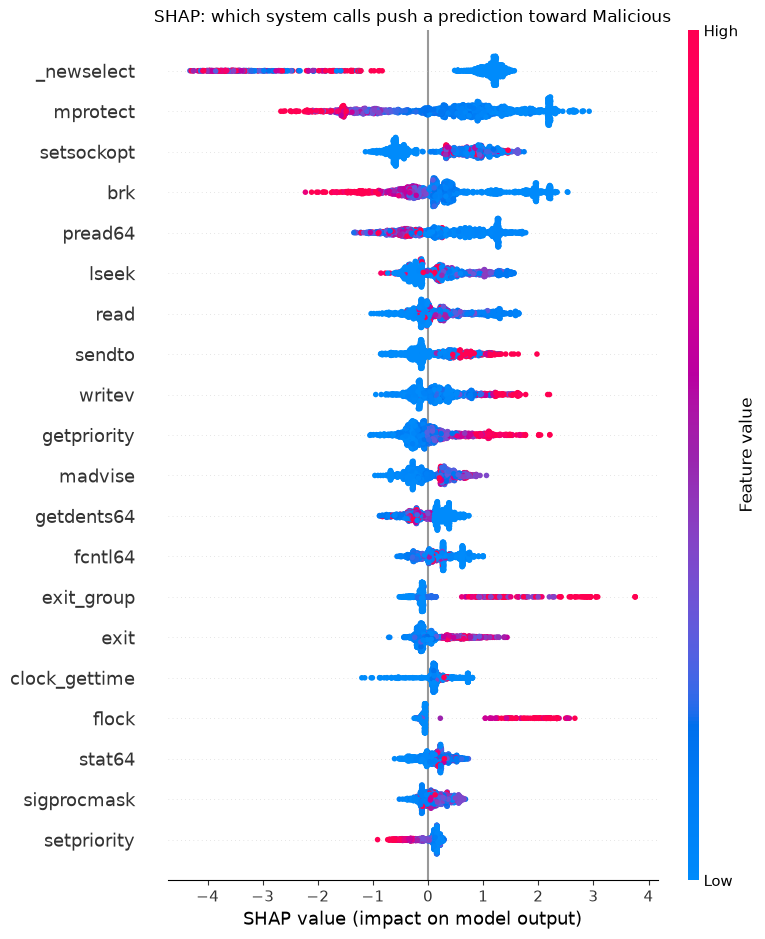

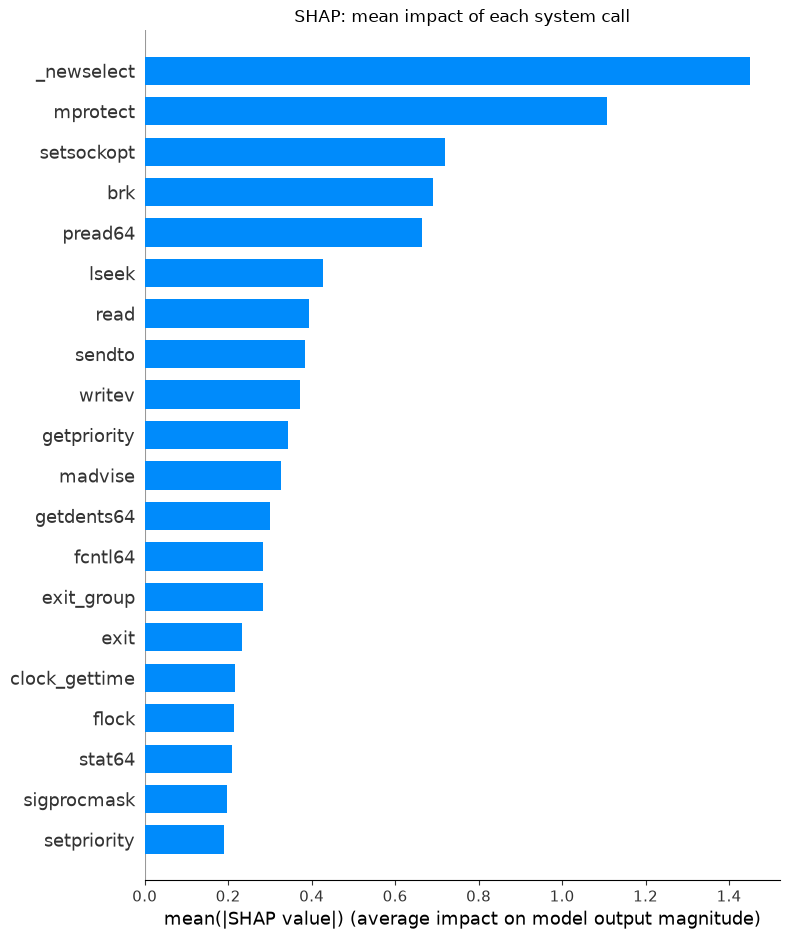

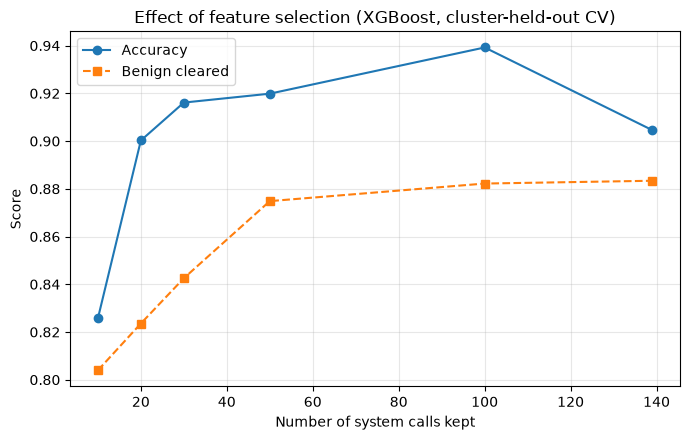


--- Example prediction (test app #0) ---
Prediction: BENIGN | probability 1.2% | actual: MALICIOUS
   _newselect                   count=50       SHAP -3.605 (toward BENIGN)
   setpriority                  count=118      SHAP -0.655 (toward BENIGN)
   exit                         count=43       SHAP +0.616 (toward MALICIOUS)
   rename                       count=24       SHAP -0.611 (toward BENIGN)
   mprotect                     count=590      SHAP -0.590 (toward BENIGN)

Best model by cluster-held-out F1: XGBoost
Saved models, tables and charts to ./dynamic_outputs_v2/


In [1]:
# =============================================================================
# PHASE 2 (v2): DYNAMIC ANALYSIS MODULE on REAL SYSTEM CALLS  (CICMalDroid2020)
# Uses only the 139 Linux system calls (what a live `strace` run can capture).
# Two-stage feature selection (Information Gain -> Extra Trees, top 50)
# Multi-Branch TCN vs BiLSTM vs Transformer vs XGBoost
# Honest evaluation: random split AND "cluster-held-out" cross-validation
# (whole groups of similar apps are kept out of training, which mimics unseen malware families)
# =============================================================================
import os, time, warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, TensorDataset
import shap
import xgboost as xgb
from scipy.stats import binomtest
from sklearn.cluster import KMeans
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, GroupKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve,
                             average_precision_score)

warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)

# -----------------------------------------------------------------------------
# >>> SETTINGS <<<
# -----------------------------------------------------------------------------
CSV_PATH = "feature_vectors_syscallsbinders_frequency_5_Cat.csv"   # the 470-feature CICMalDroid file
OUT_DIR = "dynamic_outputs_v2"
TOP_K = 50            # system calls kept after feature selection
IG_CANDIDATES = 100   # kept after the Information Gain stage
EPOCHS = 25
N_CLUSTERS = 200      # behaviour clusters used for the cluster-held-out evaluation
os.makedirs(OUT_DIR, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODELS = ["TCN (Multi-Branch)", "BiLSTM", "Transformer", "XGBoost"]

# The 139 Linux system calls of the CICMalDroid2020 syscall features (same names `strace` reports)
SYSCALLS = ['__arm_nr_cacheflush', '__arm_nr_set_tls', '_llseek', '_newselect', 'accept', 'access', 'bind', 'brk', 'capset', 'chdir', 'chmod', 'chown32', 'clock_getres', 'clock_gettime', 'clone', 'close', 'connect', 'dup', 'dup2', 'epoll_create', 'epoll_ctl', 'epoll_wait', 'eventfd2', 'execve', 'exit', 'exit_group', 'faccessat', 'fchmod', 'fchown32', 'fcntl', 'fcntl64', 'fdatasync', 'flock', 'fork', 'fstat64', 'fstatfs64', 'fsync', 'ftruncate', 'ftruncate64', 'futex', 'getcwd', 'getdents64', 'getegid32', 'geteuid32', 'getgid32', 'getgroups32', 'getpeername', 'getpgid', 'getpid', 'getppid', 'getpriority', 'getresgid32', 'getresuid32', 'getrusage', 'getsockname', 'getsockopt', 'gettid', 'gettimeofday', 'getuid32', 'inotify_add_watch', 'inotify_init', 'inotify_rm_watch', 'ioctl', 'lgetxattr', 'link', 'listen', 'lseek', 'lstat64', 'madvise', 'mkdir', 'mknod', 'mlock', 'mmap2', 'mount', 'mprotect', 'mremap', 'msync', 'munlock', 'munmap', 'nanosleep', 'open', 'pipe', 'pipe2', 'poll', 'prctl', 'pread64', 'ptrace', 'pwrite64', 'read', 'readlink', 'recvfrom', 'recvmsg', 'rename', 'rmdir', 'rt_sigprocmask', 'rt_sigtimedwait', 'sched_get_priority_max', 'sched_get_priority_min', 'sched_getparam', 'sched_getscheduler', 'sched_setaffinity', 'sched_setscheduler', 'sched_yield', 'sendmsg', 'sendto', 'setgid32', 'setgroups32', 'setitimer', 'setpgid', 'setpriority', 'setresgid32', 'setresuid32', 'setrlimit', 'setsid', 'setsockopt', 'setuid32', 'shutdown', 'sigaction', 'sigaltstack', 'sigprocmask', 'sigsuspend', 'socket', 'socketpair', 'stat64', 'statfs64', 'symlink', 'sysinfo', 'timer_create', 'timer_settime', 'truncate', 'ugetrlimit', 'umask', 'uname', 'unlink', 'utimes', 'vfork', 'wait4', 'write', 'writev']

# =============================================================================
# STEP 1: LOAD, KEEP ONLY SYSTEM CALLS, REMOVE DUPLICATES
# =============================================================================
df = pd.read_csv(CSV_PATH)
missing = [c for c in SYSCALLS if c not in df.columns]
assert not missing, f"These syscall columns are missing from the CSV: {missing}"
n0 = len(df)
tmp = df[SYSCALLS].copy()
tmp["y"] = (df["Class"] != 5).astype(int)          # Benign = 0, Malicious = 1
tmp["cls"] = df["Class"]                           # 1 Adware, 2 Banking, 3 SMS, 4 Riskware, 5 Benign
conflict = tmp.groupby(SYSCALLS)["y"].transform("nunique") > 1       # identical behaviour, different labels
tmp = tmp[~conflict].drop_duplicates(subset=SYSCALLS).reset_index(drop=True)
X, y, cls = tmp[SYSCALLS], tmp["y"], tmp["cls"]
print(f"Loaded {n0} apps; kept {len(X)} unique apps with {X.shape[1]} system-call features")
print(f"Benign: {(y == 0).sum()} | Malicious: {(y == 1).sum()}  (malware is {y.mean():.1%} of the data)")

# Behaviour clusters (no labels used): apps in the same cluster behave alike, like a malware family
Zall = StandardScaler().fit_transform(np.log1p(X.values))
groups = KMeans(N_CLUSTERS, n_init=3, random_state=SEED).fit_predict(Zall)

# =============================================================================
# STEP 2: MODELS
# =============================================================================
class Chomp1d(nn.Module):
    def __init__(self, n): super().__init__(); self.n = n
    def forward(self, x): return x[:, :, :-self.n] if self.n > 0 else x

class TemporalBlock(nn.Module):
    def __init__(self, cin, cout, k, d):
        super().__init__()
        pad = (k - 1) * d
        self.c1 = nn.Conv1d(cin, cout, k, padding=pad, dilation=d); self.ch1 = Chomp1d(pad)
        self.c2 = nn.Conv1d(cout, cout, k, padding=pad, dilation=d); self.ch2 = Chomp1d(pad)
        self.relu = nn.ReLU()
        self.down = nn.Conv1d(cin, cout, 1) if cin != cout else None
    def forward(self, x):
        o = self.relu(self.ch1(self.c1(x)))
        o = self.relu(self.ch2(self.c2(o)))
        return self.relu(o + (x if self.down is None else self.down(x)))

class TCNBranch(nn.Module):
    def __init__(self, cin, channels, k):
        super().__init__()
        layers = [TemporalBlock(cin if i == 0 else channels[i - 1], channels[i], k, 2 ** i)
                  for i in range(len(channels))]
        self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)

class MultiBranchTCN(nn.Module):
    """Two parallel TCN branches (kernel 2 = short-range, kernel 4 = long-range)."""
    def __init__(self, channels=(16, 32)):
        super().__init__()
        self.short = TCNBranch(1, channels, 2)
        self.long = TCNBranch(1, channels, 4)
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.head = nn.Sequential(nn.Linear(channels[-1] * 2, 32), nn.ReLU(), nn.Dropout(0.3), nn.Linear(32, 2))
    def forward(self, x):                      # x: (batch, 1, n_features)
        a = self.pool(self.short(x)).squeeze(-1)
        b = self.pool(self.long(x)).squeeze(-1)
        return self.head(torch.cat([a, b], dim=1))

class BiLSTM(nn.Module):
    def __init__(self, hidden=32):
        super().__init__()
        self.lstm = nn.LSTM(1, hidden, batch_first=True, bidirectional=True)
        self.head = nn.Sequential(nn.Linear(hidden * 2, 32), nn.ReLU(), nn.Dropout(0.3), nn.Linear(32, 2))
    def forward(self, x):
        _, (h, _) = self.lstm(x.permute(0, 2, 1))
        return self.head(torch.cat([h[0], h[1]], dim=1))

class TransformerClf(nn.Module):
    def __init__(self, seq_len, d_model=32, nhead=4, layers=2):
        super().__init__()
        self.proj = nn.Linear(1, d_model)
        self.pos = nn.Parameter(torch.randn(1, seq_len, d_model) * 0.02)
        enc = nn.TransformerEncoderLayer(d_model, nhead, dim_feedforward=64, dropout=0.2, batch_first=True)
        self.enc = nn.TransformerEncoder(enc, layers)
        self.head = nn.Sequential(nn.Linear(d_model, 32), nn.ReLU(), nn.Dropout(0.3), nn.Linear(32, 2))
    def forward(self, x):
        h = self.enc(self.proj(x.permute(0, 2, 1)) + self.pos)
        return self.head(h.mean(dim=1))

def train_net(net, Xtr, ytr, epochs=EPOCHS, bs=64):
    net = net.to(DEVICE)
    Xt = torch.tensor(Xtr, dtype=torch.float32).unsqueeze(1)
    yt = torch.tensor(ytr, dtype=torch.long)
    loader = DataLoader(TensorDataset(Xt, yt), batch_size=bs, shuffle=True)
    counts = np.bincount(ytr, minlength=2)
    w = torch.tensor(1.0 / counts, dtype=torch.float32); w = (w / w.sum() * 2).to(DEVICE)
    loss_fn = nn.CrossEntropyLoss(weight=w)
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    for _ in range(epochs):
        net.train()
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad(); loss_fn(net(xb), yb).backward(); opt.step()
    return net

def make_net(name, n_feat):
    return {"TCN (Multi-Branch)": lambda: MultiBranchTCN(), "BiLSTM": lambda: BiLSTM(),
            "Transformer": lambda: TransformerClf(n_feat)}[name]()

def net_prob(net, Xte):
    net.eval()
    with torch.no_grad():
        return torch.softmax(net(torch.tensor(Xte, dtype=torch.float32).unsqueeze(1).to(DEVICE)), dim=1)[:, 1].cpu().numpy()

def select_features(Xtr, ytr, k=TOP_K):
    """Stage 1: Information Gain (mutual information) -> top IG_CANDIDATES.
       Stage 2: Extra Trees (Gini importance) -> top k."""
    mi = pd.Series(mutual_info_classif(Xtr, ytr, discrete_features=False, random_state=SEED), index=Xtr.columns)
    cand = mi.sort_values(ascending=False).head(max(IG_CANDIDATES, k)).index.tolist()
    et = ExtraTreesClassifier(n_estimators=300, random_state=SEED, n_jobs=-1).fit(Xtr[cand], ytr)
    gini = pd.Series(et.feature_importances_, index=cand).sort_values(ascending=False)
    return gini.head(k).index.tolist(), gini

def make_xgb(ytr):
    return xgb.XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, eval_metric="logloss",
                             scale_pos_weight=(ytr == 0).sum() / (ytr == 1).sum(), random_state=SEED, n_jobs=-1)

def run_pipeline(Xtr, ytr, Xte, keep_artifacts=False):
    top, gini = select_features(Xtr, ytr)
    scaler = StandardScaler().fit(np.log1p(Xtr[top].values))           # log1p tames heavy-tailed counts
    Ztr, Zte = scaler.transform(np.log1p(Xtr[top].values)), scaler.transform(np.log1p(Xte[top].values))
    probs, nets = {}, {}
    for name in MODELS[:3]:
        t0 = time.time()
        net = train_net(make_net(name, len(top)), Ztr, ytr.values)
        probs[name], nets[name] = net_prob(net, Zte), net
        print(f"      {name:20s} trained in {time.time() - t0:5.1f}s", flush=True)
    xg = make_xgb(ytr).fit(Xtr[top], ytr)
    probs["XGBoost"] = xg.predict_proba(Xte[top])[:, 1]
    art = dict(top=top, gini=gini, scaler=scaler, nets=nets, xgb=xg) if keep_artifacts else None
    return probs, art

def xgb_only(Xtr, ytr, Xte, k):
    top = select_features(Xtr, ytr, k)[0] if k < Xtr.shape[1] else list(Xtr.columns)
    return make_xgb(ytr).fit(Xtr[top], ytr).predict_proba(Xte[top])[:, 1]

def to_shares(frame):
    """Each syscall's share of all syscalls the app made (removes the effect of how long the app ran)."""
    return frame.div(frame.sum(axis=1).replace(0, 1), axis=0)

def xgb_only_shares(Xtr, ytr, Xte, k):
    top = select_features(Xtr, ytr, k)[0]                      # choose syscalls on counts, then use their shares
    Str, Ste = to_shares(Xtr), to_shares(Xte)
    return make_xgb(ytr).fit(Str[top], ytr).predict_proba(Ste[top])[:, 1]

def metrics(yt, p):
    pred = (p >= 0.5).astype(int)
    return {"Accuracy": accuracy_score(yt, pred), "Precision": precision_score(yt, pred),
            "Recall (malware caught)": recall_score(yt, pred),
            "Specificity (benign cleared)": recall_score(yt, pred, pos_label=0),
            "F1": f1_score(yt, pred), "ROC-AUC": roc_auc_score(yt, p)}

def mean_std(rows):
    d = pd.DataFrame(rows)
    return {k: f"{d[k].mean():.4f} ± {d[k].std():.4f}" for k in d.columns}

def mcnemar_exact(yt, p1, p2):
    c1 = ((p1 >= 0.5).astype(int) == np.asarray(yt)); c2 = ((p2 >= 0.5).astype(int) == np.asarray(yt))
    b, c = int((c1 & ~c2).sum()), int((~c1 & c2).sum())
    return b, c, (1.0 if b + c == 0 else binomtest(min(b, c), b + c, 0.5).pvalue)

def mcnemar_table(yt, probs, title):
    rows = []
    for other in MODELS[1:]:
        b, c, p = mcnemar_exact(yt, probs["TCN (Multi-Branch)"], probs[other])
        rows.append({"Comparison": f"TCN vs {other}", "Only TCN correct": b, "Only other correct": c,
                     "p-value": round(p, 4), "Significant after Bonferroni (alpha 0.05/3)": "yes" if p < 0.05 / 3 else "no"})
    t = pd.DataFrame(rows)
    print(f"\n{title}"); print(t.to_string(index=False))
    return t

# Checkpoints: a finished run is saved, so if the script is interrupted it resumes instead of retraining.
# (To start completely fresh, delete the ckpt_*.pkl files inside the output folder.)
def cached(name, fn):
    path = f"{OUT_DIR}/ckpt_{name}_{TOP_K}_{EPOCHS}_{N_CLUSTERS}_{len(X)}.pkl"
    if os.path.exists(path):
        print(f"      (resumed: loaded saved result '{name}')", flush=True)
        return joblib.load(path)
    res = fn(); joblib.dump(res, path)
    return res

# =============================================================================
# STEP 3: MAIN RANDOM 80/20 SPLIT (for comparison with other papers)
# =============================================================================
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("\n>>> A. Main run: random 80/20 split", flush=True)
probs, art = cached("main", lambda: run_pipeline(Xtr, ytr, Xte, keep_artifacts=True))
test_table = pd.DataFrame({m: metrics(yte, probs[m]) for m in MODELS}).T
print("\n=== A. RANDOM 80/20 TEST SET ==="); print(test_table.round(4).to_string())
print(f"\nTop {TOP_K} system calls were selected on the training data only. Top 15:")
for i, (f, v) in enumerate(art["gini"].head(15).items(), 1):
    print(f"  {i:2d}. {f:28s} Gini {v:.4f}")
mc_main = mcnemar_table(yte, probs, "McNemar (random split), TCN vs each other model:")

# =============================================================================
# STEP 4: CLUSTER-HELD-OUT 5-FOLD CROSS-VALIDATION  (the honest, headline estimate)
# =============================================================================
print("\n>>> B. Cluster-held-out 5-fold CV (4 models)", flush=True)
oof = {m: np.zeros(len(X)) for m in MODELS}
fold_rows = {m: [] for m in MODELS}
for k, (tr, va) in enumerate(GroupKFold(5).split(X, y, groups=groups), 1):
    print(f"  fold {k}/5  (train {len(tr)} / held-out {len(va)})", flush=True)
    p_fold, _ = cached(f"fold{k}", lambda: run_pipeline(X.iloc[tr], y.iloc[tr], X.iloc[va]))
    for m in MODELS:
        oof[m][va] = p_fold[m]
        fold_rows[m].append(metrics(y.iloc[va], p_fold[m]))
cv_table = pd.DataFrame({m: mean_std(r) for m, r in fold_rows.items()}).T
pooled_table = pd.DataFrame({m: metrics(y, oof[m]) for m in MODELS}).T
print("\n=== B. CLUSTER-HELD-OUT 5-FOLD CV (mean ± std over folds) ==="); print(cv_table.to_string())
print("\n=== B. same, all held-out predictions pooled ==="); print(pooled_table.round(4).to_string())
mc_cv = mcnemar_table(y, oof, "McNemar on pooled cluster-held-out predictions, TCN vs each other model:")

# =============================================================================
# STEP 5: OTHER CHECKS (XGBoost only, fast)
# =============================================================================
print("\n>>> C. Random 5-fold CV for XGBoost (selection redone inside each fold)", flush=True)
rr = [metrics(y.iloc[va], xgb_only(X.iloc[tr], y.iloc[tr], X.iloc[va], TOP_K))
      for tr, va in StratifiedKFold(5, shuffle=True, random_state=SEED).split(X, y)]
rand_cv = pd.DataFrame({"XGBoost (random 5-fold)": mean_std(rr)}).T
print(rand_cv.to_string())

print("\n>>> D. Accuracy vs number of system calls kept (XGBoost, cluster-held-out)", flush=True)
krows = []
for K in [10, 20, 30, 50, 100, 139]:
    r = [metrics(y.iloc[va], xgb_only(X.iloc[tr], y.iloc[tr], X.iloc[va], K))
         for tr, va in GroupKFold(5).split(X, y, groups=groups)]
    krows.append({"features kept": K, "Accuracy": np.mean([x["Accuracy"] for x in r]), "F1": np.mean([x["F1"] for x in r]),
                  "Specificity (benign cleared)": np.mean([x["Specificity (benign cleared)"] for x in r])})
k_table = pd.DataFrame(krows).set_index("features kept")
print(k_table.round(4).to_string())

print("\n>>> E. Detecting a malware category the model has NEVER seen (XGBoost)", flush=True)
cat_names = {1: "Adware", 2: "Banking", 3: "SMS malware", 4: "Riskware"}
ben = np.where(cls.values == 5)[0]
np.random.RandomState(SEED).shuffle(ben)
ben_te, ben_tr = ben[:len(ben) // 5], ben[len(ben) // 5:]
cat_rows = []
for c, nm in cat_names.items():
    te = np.r_[np.where(cls.values == c)[0], ben_te]
    tr = np.r_[np.where((cls.values != c) & (cls.values != 5))[0], ben_tr]
    p = xgb_only(X.iloc[tr], y.iloc[tr], X.iloc[te], TOP_K); t = y.iloc[te].values
    cat_rows.append({"Unseen category": nm, "malware apps": int((t == 1).sum()),
                     "malware caught": f"{((p[t == 1] >= .5).mean()):.1%}", "benign cleared": f"{((p[t == 0] < .5).mean()):.1%}"})
cat_table = pd.DataFrame(cat_rows)
print(cat_table.to_string(index=False))

print("\n>>> F. XGBoost on normalised shares instead of raw counts (cluster-held-out)", flush=True)
sh = [metrics(y.iloc[va], xgb_only_shares(X.iloc[tr], y.iloc[tr], X.iloc[va], TOP_K))
      for tr, va in GroupKFold(5).split(X, y, groups=groups)]
shares_cv = pd.DataFrame({"XGBoost on shares (cluster-held-out)": mean_std(sh)}).T
print(shares_cv.to_string())

# =============================================================================
# STEP 6: CHARTS
# =============================================================================
g = art["gini"].head(20).iloc[::-1]
plt.figure(figsize=(8, 6)); plt.barh(g.index, g.values, color="#4C78A8")
plt.xlabel("Gini importance (Extra Trees)"); plt.title("Dynamic Module: Top 20 System Calls")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/1_feature_importance.png", dpi=200); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, m in zip(axes, MODELS):
    ConfusionMatrixDisplay(confusion_matrix(y, (oof[m] >= .5).astype(int)),
                           display_labels=["Benign", "Malicious"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(m)
fig.suptitle("Confusion matrices: cluster-held-out cross-validation (all held-out predictions pooled)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/2_confusion_matrices.png", dpi=200); plt.show()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 5))
for m in MODELS:
    fpr, tpr, _ = roc_curve(y, oof[m]); a1.plot(fpr, tpr, label=f"{m} (AUC={roc_auc_score(y, oof[m]):.3f})")
    pr, rc, _ = precision_recall_curve(y, oof[m]); a2.plot(rc, pr, label=f"{m} (AP={average_precision_score(y, oof[m]):.3f})")
a1.plot([0, 1], [0, 1], "k--", alpha=.4)
a1.set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="ROC (cluster-held-out CV)")
a2.set(xlabel="Recall", ylabel="Precision", title="Precision-Recall (cluster-held-out CV)")
a1.legend(loc="lower right"); a2.legend(loc="lower left")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/3_roc_pr_curves.png", dpi=200); plt.show()

explainer = shap.TreeExplainer(art["xgb"])
Xs = Xte[art["top"]].sample(n=min(1500, len(Xte)), random_state=SEED)
sv = explainer.shap_values(Xs)
plt.figure(); shap.summary_plot(sv, Xs, max_display=20, show=False)
plt.title("SHAP: which system calls push a prediction toward Malicious")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/4_shap_summary.png", dpi=200, bbox_inches="tight"); plt.show()
plt.figure(); shap.summary_plot(sv, Xs, plot_type="bar", max_display=20, show=False)
plt.title("SHAP: mean impact of each system call")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/5_shap_bar.png", dpi=200, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(k_table.index, k_table["Accuracy"], "o-", label="Accuracy")
ax.plot(k_table.index, k_table["Specificity (benign cleared)"], "s--", label="Benign cleared")
ax.set(xlabel="Number of system calls kept", ylabel="Score", title="Effect of feature selection (XGBoost, cluster-held-out CV)")
ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/6_accuracy_vs_features.png", dpi=200); plt.show()

def explain_one(i=None, top_n=5):
    i = int(np.where(yte.values == 1)[0][0]) if i is None else i
    row = Xte[art["top"]].iloc[[i]]
    p = float(art["xgb"].predict_proba(row)[:, 1][0]); s = explainer.shap_values(row)[0]
    print(f"\n--- Example prediction (test app #{i}) ---")
    print(f"Prediction: {'MALICIOUS' if p >= .5 else 'BENIGN'} | probability {p:.1%} | actual: {'MALICIOUS' if yte.iloc[i] else 'BENIGN'}")
    for j in np.argsort(-np.abs(s))[:top_n]:
        print(f"   {row.columns[j]:28s} count={row.iloc[0, j]:<8g} SHAP {s[j]:+.3f} ({'toward MALICIOUS' if s[j] > 0 else 'toward BENIGN'})")
explain_one()

# =============================================================================
# STEP 7: FINAL MODEL FOR THE LIVE DEMO  (refit on ALL apps)
# The numbers above are the evaluation; this refit just uses all the data for the deployable model.
# =============================================================================
best = pooled_table["F1"].idxmax()
print(f"\nBest model by cluster-held-out F1: {best}")
top_all, gini_all = select_features(X, y)
scaler_all = StandardScaler().fit(np.log1p(X[top_all].values))
final_xgb = make_xgb(y).fit(X[top_all], y)
final_xgb_share = make_xgb(y).fit(to_shares(X)[top_all], y)
final_tcn = train_net(make_net("TCN (Multi-Branch)", len(top_all)), scaler_all.transform(np.log1p(X[top_all].values)), y.values)
bundle = {"all_syscalls": SYSCALLS, "top_features": top_all, "xgb": final_xgb, "xgb_share": final_xgb_share, "scaler": scaler_all, "best_model": best,
          "note": "Trained on CICMalDroid2020 syscall counts. Live strace counts come from a different environment, "
                  "so live predictions are a demonstration, not validated."}
joblib.dump(bundle, f"{OUT_DIR}/dynamic_model.joblib")
torch.save(final_tcn.state_dict(), f"{OUT_DIR}/tcn_weights.pt")
for name, t in [("test_results", test_table.round(4)), ("cv_results_cluster_heldout", cv_table),
                ("pooled_results_cluster_heldout", pooled_table.round(4)), ("cv_results_random_xgboost", rand_cv), ("cv_results_shares_xgboost", shares_cv),
                ("feature_count_analysis", k_table.round(4)), ("mcnemar_random_split", mc_main),
                ("mcnemar_cluster_heldout", mc_cv), ("unseen_category", cat_table)]:
    t.to_csv(f"{OUT_DIR}/{name}.csv", index=not isinstance(t.index, pd.RangeIndex))
print(f"Saved models, tables and charts to ./{OUT_DIR}/")

def predict_dynamic(syscall_counts, mode="counts", model_path=f"{OUT_DIR}/dynamic_model.joblib"):
    """syscall_counts: dict {syscall_name: count} (missing syscalls = 0). Returns the malware probability.
    mode="counts": use raw counts.  mode="shares": use each syscall's share of the total (recommended for live runs,
    because a short live run makes smaller counts than the dataset's runs)."""
    b = joblib.load(model_path)
    row = pd.DataFrame([[syscall_counts.get(s, 0) for s in b["all_syscalls"]]], columns=b["all_syscalls"])
    if mode == "shares":
        return float(b["xgb_share"].predict_proba(to_shares(row)[b["top_features"]])[:, 1][0])
    return float(b["xgb"].predict_proba(row[b["top_features"]])[:, 1][0])

In [1]:
import sklearn, xgboost, shap, joblib, numpy, pandas, sys
print(sys.version.split()[0])
for m in [sklearn, xgboost, shap, joblib, numpy, pandas]:
    print(f"{m.__name__}=={m.__version__}")
joblib.load("static_outputs/static_model.joblib")
print("static model loads OK")

3.14.6
sklearn==1.9.0
xgboost==3.4.1
shap==0.53.0
joblib==1.5.3
numpy==2.4.6
pandas==3.0.3
static model loads OK
